# Hielo v1.1 · Hielo en el polo sur lunar (Diviner + LEND) y rugosidad de radar (Mini-RF)

**Proyecto:** Pathfinders42 · NASA Space Apps Challenge 2026 (análogos terrestres de la Luna y Marte).
**Versión anterior:** `hielo_v1` (14 nov 2026, ver su sección de conclusiones y `claude/hielo_v1_cierre.md`).
**Recursos oficiales del reto que usa:** *NASA LRO* y *LRO Diviner* (PDS Geosciences).

## Qué aprendimos en v1 y qué cambia aquí

`hielo_v1` comparó tres instrumentos de LRO en los 12 sitios por debajo de −80°. Tres resultados nos obligan a
cambiar el método:

| Hallazgo de v1 | Consecuencia en v1.1 |
|---|---|
| Todo el casquete polar tiene ~1 % menos neutrones que las latitudes medias: el polo entero está enriquecido en hidrógeno. Comparar con 55–60° S hacía que casi todos los sitios dieran «señal». | LEND da señal solo si el sitio tiene **más hidrógeno que el resto del polo**: exceso sobre la mediana de los discos al azar ≥ 2σ **y** percentil ≥ 75. |
| Cuanto más hielo estable tiene un sitio según Diviner, **menos** píxeles con CPR > 1 tiene (ρ = −0,73, p = 0,007). Mini-RF ve rugosidad, no hielo. | Mini-RF **sale del recuento de pruebas de hielo** y pasa a ser un indicador de **rugosidad de radar** para el uso «aterrizaje y movilidad». |
| Con solo 12 sitios y un radio elegido a mano (20 km), no sabíamos cuánto dependía el resultado del radio. | **Prueba de sensibilidad**: repetimos LEND con radios de 15, 20 y 30 km. Solo es robusta la señal que aguanta en los tres. |

Además: el mapa de LEND se suaviza (en v1 salían rayas radiales) y el zoom se adapta al tamaño de cada sitio.

## Qué produce
- `04_resultados/hielo_v1.1/hielo_lro_sitios.csv`, `sensibilidad_lend.csv`, `registro_hielo_v1.1.json` y `figuras/`.
- `06_web/hielo_v1.1/hielo_lro.json`: la capa `hielo_lro` para la API (sustituye a la de v1 en `manifest.json`).

## Cómo usarlo
Ejecuta todas las celdas. Usa la misma caché que v1 (`03_datos/cache_api/hielo_lro/`): si ya ejecutaste v1, no
descarga nada. Al final, la sección de **conclusiones** queda vacía para rellenarla con los resultados.

## Glosario rápido

- **PSR** (*permanently shadowed region*): zona que nunca recibe luz del Sol; en los polos de la Luna hay fondos de
  cráter a menos de −160 °C desde hace miles de millones de años. Son trampas frías para el agua.
- **Hielo estable (Diviner PRP)**: dónde la temperatura es tan baja que el hielo cerca de la superficie no se sublima.
  `f_hielo` es la fracción del sitio donde pasa. **Estable no significa presente**: dice dónde *podría* haber hielo.
- **Neutrones epitérmicos y supresión (LEND)**: los rayos cósmicos arrancan neutrones del suelo; el hidrógeno los
  frena. Menos neutrones epitérmicos = más hidrógeno. Supresión = 1 − tasa / tasa de referencia.
- **Exceso sobre el polo**: supresión del sitio menos la supresión mediana de 2000 discos al azar del casquete.
  Responde a «¿tiene este sitio más hidrógeno que un lugar cualquiera del polo?».
- **σ (sigma) y error estadístico**: el error de conteo de LEND (ruido de Poisson: contar pocos neutrones da cifras
  que bailan). Un exceso de 2σ significa que el exceso es el doble de lo que cabría esperar solo por ese ruido.
- **Errores sistemáticos**: los que no son ruido de conteo: el fondo de neutrones que genera la propia nave, la
  altura de la órbita (no es la misma en todas las celdas) o la pérdida de sensibilidad de los detectores con los
  años. No están en el error estadístico; por eso exigimos además el percentil frente a los discos al azar, que sí
  los recogen.
- **CPR (Mini-RF)**: cociente de polarización circular del eco de radar. Alto (> 1) con hielo enterrado **o** con
  superficies llenas de bloques del tamaño de la longitud de onda (12,6 cm). En los polos domina lo segundo.
- **Rugosidad de radar**: fracción del sitio con CPR > 1, comparada con el resto del polo. Es un indicador de
  rugosidad a escala de decímetros (bloques y piedras), útil para aterrizar y moverse con un rover.
- **Prueba de sensibilidad**: repetir el cálculo cambiando un parámetro elegido a mano para ver si la conclusión
  depende de él.
- **Proyección estereográfica polar**: plano centrado en el polo, en km, para medir distancias y áreas sin la
  deformación de la latitud y la longitud.

## 1. Entorno, rutas y parámetros

In [1]:
import json
import math
import os
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree
from shapely import contains_xy
from shapely.geometry import Point, Polygon

try:  # En Colab montamos Drive; fuera de Colab se usa la variable HACKATHON_BASE
    from google.colab import drive

    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/Hackathon Nasa")
except ImportError:
    BASE = Path(os.environ.get("HACKATHON_BASE", ".")).resolve()

VERSION = "hielo_v1.1"
WEB = BASE / "06_web"
CACHE = BASE / "03_datos" / "cache_api" / "hielo_lro"  # la misma caché que hielo_v1
RES = BASE / "04_resultados" / VERSION
FIG = RES / "figuras"
for carpeta in (CACHE, FIG, WEB / VERSION):
    carpeta.mkdir(parents=True, exist_ok=True)

print("Base del proyecto:", BASE)
print("¿Existe 06_web/sitios_v0/sitios.geojson?", (WEB / "sitios_v0" / "sitios.geojson").exists())
print("¿Existe 06_web/hielo_v0/hielo.json?", (WEB / "hielo_v0" / "hielo.json").exists())
print("Archivos ya en la caché:", sorted(p.name for p in CACHE.glob("*")))

Mounted at /content/drive
Base del proyecto: /content/drive/MyDrive/Hackathon Nasa
¿Existe 06_web/sitios_v0/sitios.geojson? True
¿Existe 06_web/hielo_v0/hielo.json? True
Archivos ya en la caché: ['global_cpr_32ppd_simp_0c.lbl', 'lend_rdr_ald.fmt', 'lend_rdr_alde_20090915.dat', 'lend_rdr_alde_20111211.dat', 'lend_rdr_alds_20090915.dat', 'lend_rdr_alds_20111211.dat', 'minirf_cpr_32ppd_filas_5440_5760.img']


**Parámetros.** Todos aquí, para poder cambiarlos sin tocar el resto.

- `RADIO_PUNTO_KM`: radio del disco que representa un sitio puntual (IM-1, IM-2, Chang'e 7). Las regiones Artemis
  son polígonos de ~400 km² (un disco de ~11 km), así que 10 km deja los dos tipos comparables.
- `RADIO_LEND_KM`: radio en el que se promedia LEND alrededor de cada sitio. La mancha de LEND en el suelo es de
  ~10–20 km; promediar en menos sería fingir una resolución que no tiene.
- `RADIOS_SENSIBILIDAD`: radios con los que se repite LEND en la prueba de sensibilidad.
- `Z_POLO` y `PCT_SENAL`: las dos condiciones de la señal de LEND (exceso estadístico y percentil frente al polo).
- `UMBRAL_HIELO`: el mismo umbral de Diviner que en `hielo_v0` (0,25).
- `PCT_RUGOSIDAD`: cortes de percentil para clasificar la rugosidad de radar en baja, media o alta.

In [2]:
R_LUNA_KM = 1737.4          # radio medio de la Luna
LAT_CASQUETE = -80.0        # trabajamos por debajo de −80° (límite de la rejilla polar de LEND)
RADIO_PUNTO_KM = 10.0
RADIO_LEND_KM = 20.0
RADIOS_SENSIBILIDAD = (15.0, 20.0, 30.0)
RADIO_ANILLO_KM = (10.0, 30.0)  # anillo de contexto alrededor de cada sitio (Mini-RF)
N_DISCOS_AZAR = 2000
SEMILLA = 42
Z_POLO = 2.0
PCT_SENAL = 75
UMBRAL_HIELO = 0.25
PCT_RUGOSIDAD = (25, 75)    # < 25 baja · 25–75 media · ≥ 75 alta
CPR_VALIDO = (0.0, 5.0)     # fuera de este rango, el píxel se descarta (relleno o ruido)
ACTUALIZAR_MANIFEST = True  # la capa «hielo_lro» pasa a apuntar a hielo_v1.1

PDS = "https://pds-geosciences.wustl.edu/lro"
URL_MINIRF_CPR = f"{PDS}/lro-l-mrflro-5-global-mosaic-v1/lromrf_1001/data/32ppd/global_cpr_32ppd_simp_0c.img"
URL_MINIRF_LBL = URL_MINIRF_CPR.replace(".img", ".lbl")
LEND_DATA = f"{PDS}/lro-l-lend-2-edr-v1/lrolen_0xxx/data"
PERIODOS_LEND = {
    "20090915": f"{LEND_DATA}/2009/20090915",  # órbita circular de ~50 km (sep 2009 – dic 2011)
    "20111211": f"{LEND_DATA}/2011/20111211",  # órbita elíptica, periapsis bajo sobre el polo sur (dic 2011 – sep 2016)
}
URL_LEND_FMT = f"{PDS}/lro-l-lend-2-edr-v1/lrolen_0xxx/label/lend_rdr_ald.fmt"

## 2. Los sitios polares y lo que ya sabíamos (Diviner, `hielo_v0`)

Los sitios lunares de `sitios_v0` por debajo de −80°, con `f_hielo` de Diviner y la pareja de la Tierra por hielo
(`region_ht`) que calculó `hielo_v0`.

In [3]:
sitios_geo = json.loads((WEB / "sitios_v0" / "sitios.geojson").read_text(encoding="utf-8"))
hielo_v0 = json.loads((WEB / "hielo_v0" / "hielo.json").read_text(encoding="utf-8"))

filas = []
for f in sitios_geo["features"]:
    p = f["properties"]
    if p["cuerpo"] != "luna":
        continue
    h = hielo_v0["sitios"].get(p["id"], {})
    lat = h.get("lat", p.get("lat_centro"))
    lon = h.get("lon", p.get("lon_centro"))
    if lat is None or lat > LAT_CASQUETE:
        continue
    filas.append(
        {
            "sitio_id": p["id"],
            "nombre": p["nombre"],
            "tipo": p["tipo"],
            "lat": lat,
            "lon": lon,
            "geometria": f["geometry"],
            "diviner_f_hielo": h.get("f_hielo"),
            "diviner_prof_hielo": h.get("hielo_prof"),
            "pareja_hielo_tierra": h.get("region_ht"),
            "analogo_hielo_terreno_v0": h.get("analogo_hielo_terreno"),
        }
    )

sitios = pd.DataFrame(filas).sort_values("lat").reset_index(drop=True)
print(f"{len(sitios)} sitios lunares por debajo de {LAT_CASQUETE}°")
sitios[["sitio_id", "nombre", "lat", "lon", "diviner_f_hielo", "pareja_hielo_tierra", "analogo_hielo_terreno_v0"]]

12 sitios lunares por debajo de -80.0°


,sitio_id,nombre,lat,lon,diviner_f_hielo,pareja_hielo_tierra,analogo_hielo_terreno_v0
0,aterrizaje-chang-e-7,Chang'e 7,-88.800,123.400,0.393,"Askja, Islandia",No
1,artemis-de-gerlache-rim-2,de Gerlache Rim 2,-88.213,-64.544,0.262,"Provincia de Alto Badajshán, Tayikistán",No
2,artemis-slater-plain,Slater Plain,-87.152,125.570,0.541,"Askja, Islandia",No
3,artemis-haworth,Haworth,-86.745,-22.852,0.615,"Provincia de Alto Badajshán, Tayikistán",No
4,artemis-malapert-massif,Malapert Massif,-85.990,-0.236,0.210,"Provincia de Alto Badajshán, Tayikistán",No
5,artemis-nobile-rim-1,Nobile Rim 1,-85.429,37.359,0.353,"Provincia de Alto Badajshán, Tayikistán",Sí
6,artemis-mons-mouton,Mons Mouton,-85.422,31.755,0.465,"Provincia de Alto Badajshán, Tayikistán",No
7,aterrizaje-im-1-odysseus,IM-1 Odysseus,-84.900,12.900,0.968,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),Sí
8,aterrizaje-im-2-athena,IM-2 Athena,-84.791,29.196,0.453,"Askja, Islandia",Sí
9,artemis-mons-mouton-plateau,Mons Mouton Plateau,-84.245,30.049,0.194,None,—


### Del globo al plano: proyección estereográfica polar

ρ = 2R · tan(π/4 + φ/2) x = ρ · sen λ y = ρ · cos λ (R = 1737,4 km). A −80° la distorsión es menor del 1 %.
Los polígonos de Artemis se densifican antes de proyectarlos para que sus lados sigan la forma real.

In [4]:
def a_polar(lat, lon):
    # Lat/lon en grados -> x, y en km (estereográfica polar sur, esfera lunar)
    lat = np.radians(np.asarray(lat, dtype=float))
    lon = np.radians(np.asarray(lon, dtype=float))
    rho = 2 * R_LUNA_KM * np.tan(np.pi / 4 + lat / 2)
    return rho * np.sin(lon), rho * np.cos(lon)


def densificar(anillo_lonlat, pasos=20):
    # Añade puntos intermedios en cada lado del polígono (corrigiendo el salto de ±180° en longitud)
    puntos = []
    for (lon1, lat1), (lon2, lat2) in zip(anillo_lonlat[:-1], anillo_lonlat[1:]):
        dlon = (lon2 - lon1 + 540) % 360 - 180
        for t in np.linspace(0, 1, pasos, endpoint=False):
            puntos.append((lon1 + t * dlon, lat1 + t * (lat2 - lat1)))
    return puntos


def geometria_polar(fila):
    g = fila["geometria"]
    if g["type"] == "Polygon":
        lon, lat = np.array(densificar(g["coordinates"][0])).T
        x, y = a_polar(lat, lon)
        return Polygon(np.column_stack([x, y])).buffer(0)
    x, y = a_polar(fila["lat"], fila["lon"])
    return Point(float(x), float(y)).buffer(RADIO_PUNTO_KM, quad_segs=32)


sitios["geom"] = sitios.apply(geometria_polar, axis=1)
sitios["area_km2"] = sitios["geom"].apply(lambda g: g.area)
sitios["cx"] = sitios["geom"].apply(lambda g: g.centroid.x)
sitios["cy"] = sitios["geom"].apply(lambda g: g.centroid.y)
RHO_CASQUETE = float(np.hypot(*a_polar(LAT_CASQUETE, 0.0)))
print(f"Radio del casquete ≤ {LAT_CASQUETE}° en el plano: {RHO_CASQUETE:.0f} km")
sitios[["nombre", "area_km2"]].round(1)

Radio del casquete ≤ -80.0° en el plano: 304 km


,nombre,area_km2
0,Chang'e 7,314.0
1,de Gerlache Rim 2,399.1
2,Slater Plain,398.4
3,Haworth,887.9
4,Malapert Massif,442.1
5,Nobile Rim 1,399.4
6,Mons Mouton,255.8
7,IM-1 Odysseus,314.0
8,IM-2 Athena,314.0
9,Mons Mouton Plateau,4399.6


## 3. Mini-RF: rugosidad de radar

Mismo producto que en v1: el **mosaico global de CPR** de Mini-RF (`LRO-L-MRFLRO-5-GLOBAL-MOSAIC-V1.0`), banda S,
julio 2009 – diciembre 2010, 32 px/grado. Solo leemos las filas por debajo de −80° (HTTP *Range*, 15 MB).

**Qué cambia:** en v1 vimos que, en estos sitios, el CPR alto sigue los bordes de cráter y los macizos (rugosos y
más templados), no los fondos fríos. Así que aquí **no lo contamos como prueba de hielo**: lo usamos como medida de
**rugosidad a escala de decímetros**. La métrica principal es la **fracción del sitio con CPR > 1**, que separa
mejor los sitios rugosos que la mediana (la mediana apenas se mueve: casi todo el polo tiene CPR 0,4–0,6).

In [5]:
def descargar(url, destino, rango=None):
    # Descarga con caché: si el archivo ya está en Drive, no se vuelve a pedir
    destino = Path(destino)
    if destino.exists() and destino.stat().st_size > 0:
        return destino
    cabeceras = {"Range": f"bytes={rango[0]}-{rango[1]}"} if rango else {}
    print("Descargando", url, f"(bytes {rango[0]}–{rango[1]})" if rango else "")
    r = requests.get(url, headers=cabeceras, timeout=300)
    r.raise_for_status()
    contenido = r.content
    if rango and r.status_code == 200:  # el servidor ignoró el Range y mandó el archivo entero
        contenido = contenido[rango[0] : rango[1] + 1]
    destino.write_bytes(contenido)
    return destino


def leer_lbl_pds3(texto):
    # Lee pares CLAVE = valor de una etiqueta PDS3 (suficiente para las claves de la imagen)
    valores = {}
    for linea in texto.splitlines():
        if "=" in linea:
            clave, valor = linea.split("=", 1)
            valores.setdefault(clave.strip(), valor.strip().strip('"').split("<")[0].strip())
    return valores


lbl = leer_lbl_pds3(descargar(URL_MINIRF_LBL, CACHE / "global_cpr_32ppd_simp_0c.lbl").read_text())
LINEAS, MUESTRAS = int(lbl["LINES"]), int(lbl["LINE_SAMPLES"])
PPD = float(lbl["MAP_RESOLUTION"])
LINEA_OFF, MUESTRA_OFF = float(lbl["LINE_PROJECTION_OFFSET"]), float(lbl["SAMPLE_PROJECTION_OFFSET"])
assert lbl["SAMPLE_TYPE"] == "PC_REAL" and lbl["SAMPLE_BITS"] == "32", "Formato inesperado"
assert lbl["MAP_PROJECTION_TYPE"] == "SIMPLE CYLINDRICAL"

fila0 = min(max(int(math.ceil(LINEA_OFF - 1 - LAT_CASQUETE * PPD)), 0), LINEAS - 1)
n_filas = LINEAS - fila0
bytes_fila = MUESTRAS * 4
trozo = descargar(
    URL_MINIRF_CPR, CACHE / f"minirf_cpr_32ppd_filas_{fila0}_{LINEAS}.img", (fila0 * bytes_fila, LINEAS * bytes_fila - 1)
)
cpr = np.fromfile(trozo, dtype="<f4").reshape(n_filas, MUESTRAS).astype(float)
lat_filas = (LINEA_OFF - (np.arange(fila0, LINEAS) + 1)) / PPD
lon_cols = ((np.arange(MUESTRAS) + 1) - MUESTRA_OFF) / PPD
validos = np.isfinite(cpr) & (cpr >= CPR_VALIDO[0]) & (cpr <= CPR_VALIDO[1])
print(f"Píxeles válidos: {validos.mean():.1%}  ·  CPR mediano del casquete: {np.median(cpr[validos]):.3f}")

# Píxeles de igual área (~1 km²): en cada fila, uno de cada 1/cos(φ)
px_x, px_y, px_v = [], [], []
for i, lat in enumerate(lat_filas):
    paso = max(1, int(round(1 / max(math.cos(math.radians(lat)), 1e-6))))
    cols = np.arange(0, MUESTRAS, paso)
    ok = validos[i, cols]
    if not ok.any():
        continue
    x, y = a_polar(np.full(ok.sum(), lat), lon_cols[cols][ok])
    px_x.append(x)
    px_y.append(y)
    px_v.append(cpr[i, cols][ok])
px_x, px_y, px_v = (np.concatenate(a) for a in (px_x, px_y, px_v))
arbol_px = cKDTree(np.column_stack([px_x, px_y]))
print(f"{len(px_v):,} píxeles de ~1 km² en el casquete".replace(",", "."))

Píxeles válidos: 97.1%  ·  CPR mediano del casquete: 0.490
319.476 píxeles de ~1 km² en el casquete


In [6]:
def stats_cpr(valores):
    if len(valores) == 0:
        return {"mediana": np.nan, "p90": np.nan, "frac_gt1": np.nan, "n": 0}
    return {
        "mediana": float(np.median(valores)),
        "p90": float(np.percentile(valores, 90)),
        "frac_gt1": float(np.mean(valores > 1.0)),
        "n": int(len(valores)),
    }


def dentro(geom):
    # Índices de los píxeles dentro de una geometría (primero se filtra con el rectángulo que la contiene)
    minx, miny, maxx, maxy = geom.bounds
    caja = np.where((px_x >= minx) & (px_x <= maxx) & (px_y >= miny) & (px_y <= maxy))[0]
    return caja[contains_xy(geom, px_x[caja], px_y[caja])]


res_minirf = []
for _, s in sitios.iterrows():
    en_sitio = stats_cpr(px_v[dentro(s.geom)])
    anillo = Point(s.cx, s.cy).buffer(RADIO_ANILLO_KM[1]).difference(Point(s.cx, s.cy).buffer(RADIO_ANILLO_KM[0]))
    en_anillo = stats_cpr(px_v[dentro(anillo.difference(s.geom))])
    res_minirf.append(
        {
            "minirf_cpr_mediana": en_sitio["mediana"],
            "minirf_cpr_p90": en_sitio["p90"],
            "minirf_frac_cpr_gt1": en_sitio["frac_gt1"],
            "minirf_n_px": en_sitio["n"],
            "minirf_frac_cpr_gt1_anillo": en_anillo["frac_gt1"],
        }
    )
sitios = pd.concat([sitios, pd.DataFrame(res_minirf)], axis=1)
sitios[["nombre", "minirf_cpr_mediana", "minirf_frac_cpr_gt1", "minirf_frac_cpr_gt1_anillo", "minirf_n_px"]].round(3)

,nombre,minirf_cpr_mediana,minirf_frac_cpr_gt1,minirf_frac_cpr_gt1_anillo,minirf_n_px
0,Chang'e 7,0.374,0.017,0.038,349
1,de Gerlache Rim 2,0.510,0.061,0.070,440
2,Slater Plain,0.456,0.016,0.032,445
3,Haworth,0.410,0.013,0.030,989
4,Malapert Massif,0.573,0.076,0.055,488
5,Nobile Rim 1,0.515,0.056,0.035,444
6,Mons Mouton,0.512,0.035,0.047,287
7,IM-1 Odysseus,0.523,0.060,0.083,348
8,IM-2 Athena,0.479,0.020,0.061,349
9,Mons Mouton Plateau,0.547,0.067,0.094,4880


**Comprobación de v1 con estos datos:** si Mini-RF midiera hielo, la fracción con CPR > 1 debería **subir** con la
fracción de hielo estable de Diviner. Si mide rugosidad, debería **bajar** (los fondos fríos son lisos).

In [7]:
d = sitios[["diviner_f_hielo", "minirf_frac_cpr_gt1"]].dropna()
rho_s, p = stats.spearmanr(d["diviner_f_hielo"], d["minirf_frac_cpr_gt1"])
print(f"Diviner f_hielo vs fracción con CPR > 1: ρ = {rho_s:+.2f} (p = {p:.3f}, n = {len(d)})")
print("→ Mini-RF se comporta como", "rugosidad (ρ < 0)" if rho_s < 0 else "posible indicador de hielo (ρ > 0): revisar")

Diviner f_hielo vs fracción con CPR > 1: ρ = -0.73 (p = 0.007, n = 12)
→ Mini-RF se comporta como rugosidad (ρ < 0)


## 4. LEND: los neutrones

Mismos datos que en v1: **ALD del polo sur** (`LRO-L-LEND-4/5-RDR-V1.0`) de los dos periodos de la misión, con el
detector colimado **CSETN**. Para cada periodo se calcula la tasa de referencia en 55–60° S, 240–300° E (producto
ecuatorial del mismo periodo), la supresión de cada celda y, al final, se combinan los periodos con media
ponderada por 1/error².

⚠ No convertimos a % de hielo (WEH): el fondo de neutrones de la nave, más de la mitad de la señal de CSETN, no está
restado en el producto de PDS. La supresión solo sirve **para comparar lugares entre sí**.

In [8]:
def leer_fmt_pds3(texto):
    # Columnas de un .fmt PDS3: nombre, tipo, byte inicial (base 1), bytes e items
    columnas = []
    for bloque in texto.split("OBJECT")[1:]:
        if "COLUMN" not in bloque.split("\n", 1)[0]:
            continue
        v = leer_lbl_pds3(bloque)
        if "NAME" in v and "START_BYTE" in v:
            columnas.append((v["NAME"], v.get("DATA_TYPE", ""), int(v["START_BYTE"]), int(v["BYTES"]), int(v.get("ITEMS", 1))))
    return columnas


def dtype_lend(columnas, orden):
    nombres, formatos, offsets = [], [], []
    for nombre, tipo, inicio, nbytes, items in columnas:
        if tipo == "CHARACTER":
            fmt = f"S{nbytes}"
        elif items > 1:
            fmt = (f"{orden}f4", items)
        else:
            fmt = f"{orden}f4"
        nombres.append(nombre)
        formatos.append(fmt)
        offsets.append(inicio - 1)
    return np.dtype({"names": nombres, "formats": formatos, "offsets": offsets, "itemsize": 310})


columnas_lend = leer_fmt_pds3(descargar(URL_LEND_FMT, CACHE / "lend_rdr_ald.fmt").read_text())
COL_LAT = next(c[0] for c in columnas_lend if "LATITUDE" in c[0])
COL_LON = next(c[0] for c in columnas_lend if "LONGITUDE" in c[0])


def leer_ald(ruta, lat_rango):
    # IEEE_REAL de PDS3 es big-endian. Comprobamos con las latitudes y, si no cuadran, probamos little-endian
    datos = ruta.read_bytes()
    for orden in (">", "<"):
        t = np.frombuffer(datos, dtype=dtype_lend(columnas_lend, orden))
        lat = t[COL_LAT].astype(float)
        if np.nanmin(lat) >= lat_rango[0] - 1 and np.nanmax(lat) <= lat_rango[1] + 1:
            df = pd.DataFrame(
                {
                    "lat": lat,
                    "lon": t[COL_LON].astype(float),
                    "tasa": t["CSETN_RATE"].astype(float),
                    "err": t["CSETN_ERR"].astype(float),
                }
            )
            df["lon"] = (df["lon"] + 180) % 360 - 180
            ok = np.isfinite(df["tasa"]) & np.isfinite(df["err"]) & (df["tasa"] > 0) & (df["err"] > 0)
            return df[ok].reset_index(drop=True)
    raise ValueError(f"No se pudo interpretar {ruta.name}: las latitudes no caen en {lat_rango}")


def referencia(df_ecuatorial):
    lon360 = df_ecuatorial["lon"] % 360
    zona = df_ecuatorial[(df_ecuatorial["lat"].between(-60, -55)) & (lon360.between(240, 300))]
    w = 1 / zona["err"] ** 2
    return float((zona["tasa"] * w).sum() / w.sum())


periodos = []
for inicio, carpeta in PERIODOS_LEND.items():
    sur = leer_ald(descargar(f"{carpeta}/lend_rdr_alds_{inicio}.dat", CACHE / f"lend_rdr_alds_{inicio}.dat"), (-90, -80))
    ecu = leer_ald(descargar(f"{carpeta}/lend_rdr_alde_{inicio}.dat", CACHE / f"lend_rdr_alde_{inicio}.dat"), (-80, 80))
    b = referencia(ecu)
    sur["sup"] = 1 - sur["tasa"] / b
    sur["sup_err"] = sur["err"] / b
    sur["periodo"] = inicio
    periodos.append(sur)
    print(f"{inicio}: {len(sur)} celdas · referencia {b:.3f} cps · supresión mediana del polo {sur['sup'].median():+.2%}")

todas = pd.concat(periodos)
todas["w"] = 1 / todas["sup_err"] ** 2
todas["lat_r"], todas["lon_r"] = todas["lat"].round(2), todas["lon"].round(2)
lend = (
    todas.assign(sw=todas["sup"] * todas["w"])
    .groupby(["lat_r", "lon_r"], as_index=False)
    .agg(sw=("sw", "sum"), w=("w", "sum"))
)
lend["sup"] = lend["sw"] / lend["w"]
lend["sup_err"] = 1 / np.sqrt(lend["w"])
lend = lend.rename(columns={"lat_r": "lat", "lon_r": "lon"}).drop(columns="sw")
lend["x"], lend["y"] = a_polar(lend["lat"], lend["lon"])
arbol_lend = cKDTree(lend[["x", "y"]].to_numpy())
print(f"{len(lend)} celdas combinadas · supresión mediana del polo {lend['sup'].median():+.2%}")

20090915: 14400 celdas · referencia 4.998 cps · supresión mediana del polo +1.53%
20111211: 13407 celdas · referencia 4.973 cps · supresión mediana del polo +0.94%
14400 celdas combinadas · supresión mediana del polo +1.21%


In [9]:
def stats_lend(cx, cy, radio=RADIO_LEND_KM):
    # Media ponderada (1/error²) de la supresión de las celdas a menos de `radio` km, y su error estadístico
    idx = arbol_lend.query_ball_point([cx, cy], r=radio)
    if not idx:
        return {"sup": np.nan, "err": np.nan, "n": 0}
    sel = lend.iloc[idx]
    w = 1 / sel["sup_err"] ** 2
    return {"sup": float((sel["sup"] * w).sum() / w.sum()), "err": float(1 / np.sqrt(w.sum())), "n": len(sel)}

## 5. Comparación con 2000 lugares al azar del polo

Ponemos 2000 discos al azar en el casquete (densidad uniforme en área) y calculamos en cada uno lo mismo que en los
sitios. Es la **distribución nula**: lo que tiene un lugar cualquiera del polo.

- **Rugosidad de radar:** percentil de la fracción con CPR > 1 del sitio frente a los discos al azar (mismo radio que
  un sitio típico).
- **LEND:** dos medidas complementarias:
  - **`lend_z_polo`** = (supresión del sitio − mediana de los discos al azar) / error estadístico del sitio.
    Pregunta: ¿el exceso es mayor que el ruido de conteo?
  - **`lend_percentil`** frente a los discos al azar. Pregunta: ¿es raro en el polo, contando también los
    efectos sistemáticos y la variación natural del terreno?
  - **Señal de LEND** = las dos a la vez: `lend_z_polo` ≥ 2 **y** `lend_percentil` ≥ 75.

In [10]:
rng = np.random.default_rng(SEMILLA)


def centros_azar(radio_margen):
    rho_max = RHO_CASQUETE - radio_margen
    rho = np.sqrt(rng.uniform(0, 1, N_DISCOS_AZAR)) * rho_max
    theta = rng.uniform(0, 2 * np.pi, N_DISCOS_AZAR)
    return np.column_stack([rho * np.sin(theta), rho * np.cos(theta)])


def percentil(valor, nulo):
    nulo = nulo[np.isfinite(nulo)]
    return float(stats.percentileofscore(nulo, valor, kind="mean")) if np.isfinite(valor) and len(nulo) else np.nan


# Rugosidad de radar
radio_eq = float(np.sqrt(sitios["area_km2"].median() / np.pi))
centros = centros_azar(max(RADIOS_SENSIBILIDAD))


def frac_gt1_disco(centro, radio):
    idx = arbol_px.query_ball_point(centro, r=radio)
    return float(np.mean(px_v[idx] > 1.0)) if idx else np.nan


nulo_rug = np.array([frac_gt1_disco(c, radio_eq) for c in centros])
sitios["rugosidad_radar_percentil"] = sitios["minirf_frac_cpr_gt1"].apply(lambda v: percentil(v, nulo_rug))
sitios["rugosidad_radar"] = pd.cut(
    sitios["rugosidad_radar_percentil"], bins=[-1, PCT_RUGOSIDAD[0], PCT_RUGOSIDAD[1], 101],
    labels=["baja", "media", "alta"], right=False,
).astype(str)
print(f"Radio de los discos de Mini-RF: {radio_eq:.1f} km · fracción con CPR > 1 mediana al azar: {np.nanmedian(nulo_rug):.3f}")


# LEND con cada radio de la prueba de sensibilidad
def lend_con_radio(radio):
    nulo = np.array([stats_lend(*c, radio=radio)["sup"] for c in centros])
    mediana_nula = float(np.nanmedian(nulo))
    filas = []
    for _, s in sitios.iterrows():
        r = stats_lend(s.cx, s.cy, radio=radio)
        z = (r["sup"] - mediana_nula) / r["err"] if r["n"] else np.nan
        pct = percentil(r["sup"], nulo)
        filas.append(
            {
                "sitio_id": s.sitio_id, "radio_km": radio, "lend_supresion": r["sup"], "lend_err": r["err"],
                "lend_n_celdas": r["n"], "lend_mediana_polo": mediana_nula, "lend_exceso": r["sup"] - mediana_nula,
                "lend_z_polo": z, "lend_percentil": pct,
                "senal_lend": bool(np.isfinite(z) and z >= Z_POLO and pct >= PCT_SENAL),
            }
        )
    return pd.DataFrame(filas)


sensibilidad = pd.concat([lend_con_radio(r) for r in RADIOS_SENSIBILIDAD], ignore_index=True)
for r in RADIOS_SENSIBILIDAD:
    m = sensibilidad.loc[sensibilidad["radio_km"] == r, "lend_mediana_polo"].iloc[0]
    print(f"Radio {r:.0f} km: supresión mediana del polo {m:+.2%}")

principal = sensibilidad[sensibilidad["radio_km"] == RADIO_LEND_KM].drop(columns="radio_km").set_index("sitio_id")
sitios = sitios.join(principal, on="sitio_id")
robustez = sensibilidad.groupby("sitio_id")["senal_lend"].sum().rename("lend_radios_con_senal")
sitios = sitios.join(robustez, on="sitio_id")
sitios[["nombre", "lend_supresion", "lend_exceso", "lend_err", "lend_z_polo", "lend_percentil", "senal_lend", "lend_radios_con_senal"]].round(4)

Radio de los discos de Mini-RF: 11.3 km · fracción con CPR > 1 mediana al azar: 0.039
Radio 15 km: supresión mediana del polo +1.05%
Radio 20 km: supresión mediana del polo +1.02%
Radio 30 km: supresión mediana del polo +1.01%


,nombre,lend_supresion,lend_exceso,lend_err,lend_z_polo,lend_percentil,senal_lend,lend_radios_con_senal
0,Chang'e 7,0.0142,0.0040,0.0023,1.7478,74.55,False,1
1,de Gerlache Rim 2,0.0167,0.0065,0.0026,2.5444,86.60,True,2
2,Slater Plain,0.0134,0.0032,0.0025,1.2710,70.40,False,0
3,Haworth,0.0152,0.0050,0.0023,2.1512,79.90,True,2
4,Malapert Massif,0.0156,0.0054,0.0027,2.0138,81.60,True,2
5,Nobile Rim 1,0.0175,0.0073,0.0033,2.2155,88.75,True,2
6,Mons Mouton,0.0168,0.0066,0.0033,2.0129,86.95,True,3
7,IM-1 Odysseus,0.0095,-0.0007,0.0035,-0.1902,45.75,False,0
8,IM-2 Athena,0.0177,0.0075,0.0032,2.3285,89.40,True,2
9,Mons Mouton Plateau,0.0113,0.0011,0.0034,0.3187,57.00,False,0


### Prueba de sensibilidad: ¿depende la señal de LEND del radio?

Cada columna es un radio. ✓ = señal de LEND con ese radio. Una señal que solo aparece con un radio es frágil; la que
aparece con los tres es robusta.

In [11]:
tabla_sens = sensibilidad.pivot(index="sitio_id", columns="radio_km", values="senal_lend").replace({True: "✓", False: "·"})
tabla_sens.columns = [f"{c:.0f} km" for c in tabla_sens.columns]
tabla_sens.insert(0, "nombre", sitios.set_index("sitio_id")["nombre"])
z_sens = sensibilidad.pivot(index="sitio_id", columns="radio_km", values="lend_z_polo").round(1)
z_sens.columns = [f"z {c:.0f} km" for c in z_sens.columns]
tabla_sens.join(z_sens).sort_values("nombre")

,nombre,15 km,20 km,30 km,z 15 km,z 20 km,z 30 km
sitio_id,,,,,,,
aterrizaje-chang-e-7,Chang'e 7,·,·,✓,0.3,1.7,4.4
artemis-haworth,Haworth,·,✓,✓,1.6,2.2,3.4
aterrizaje-im-1-odysseus,IM-1 Odysseus,·,·,·,-0.8,-0.2,-0.1
aterrizaje-im-2-athena,IM-2 Athena,·,✓,✓,2.0,2.3,3.1
artemis-malapert-massif,Malapert Massif,·,✓,✓,1.9,2.0,2.9
artemis-mons-mouton,Mons Mouton,✓,✓,✓,2.2,2.0,4.1
artemis-mons-mouton-plateau,Mons Mouton Plateau,·,·,·,0.6,0.3,1.4
artemis-nobile-rim-1,Nobile Rim 1,·,✓,✓,1.9,2.2,4.0
artemis-nobile-rim-2,Nobile Rim 2,·,·,·,0.2,-0.1,0.3


## 6. Veredicto de hielo por sitio

Dos pruebas independientes de hielo, con significados distintos:

| Diviner (frío) | LEND (hidrógeno) | Nivel | Qué significa |
|---|---|---|---|
| ✓ | ✓ | **frío + hidrógeno** | El hielo puede conservarse **y** hay más hidrógeno que en el resto del polo |
| ✓ | · | **solo frío** | El hielo sería estable, pero LEND no ve más hidrógeno que en un lugar cualquiera del polo |
| · | ✓ | **solo hidrógeno** | Hay más hidrógeno, pero el sitio no es frío en conjunto (puede estar en trampas frías pequeñas cercanas) |
| · | · | **sin señal** | Ninguna de las dos pruebas apunta a hielo |

Además se indica si la señal de LEND es **robusta** (aparece con los tres radios). La rugosidad de radar va aparte:
no es una prueba de hielo, es información para aterrizar y moverse.

In [12]:
sitios["senal_diviner"] = sitios["diviner_f_hielo"].fillna(0) >= UMBRAL_HIELO
niveles = {(True, True): "frío + hidrógeno", (True, False): "solo frío", (False, True): "solo hidrógeno", (False, False): "sin señal"}
sitios["nivel_hielo"] = [niveles[(bool(a), bool(b))] for a, b in zip(sitios["senal_diviner"], sitios["senal_lend"])]
sitios["lend_robusta"] = sitios["lend_radios_con_senal"] == len(RADIOS_SENSIBILIDAD)

orden = {"frío + hidrógeno": 0, "solo hidrógeno": 1, "solo frío": 2, "sin señal": 3}
columnas_tabla = [
    "nombre", "diviner_f_hielo", "lend_z_polo", "lend_percentil", "lend_radios_con_senal", "nivel_hielo",
    "rugosidad_radar", "minirf_frac_cpr_gt1", "pareja_hielo_tierra", "analogo_hielo_terreno_v0",
]
print(sitios["nivel_hielo"].value_counts().to_string())
sitios.assign(_o=sitios["nivel_hielo"].map(orden)).sort_values(["_o", "lend_z_polo"], ascending=[True, False])[columnas_tabla].round(2)

nivel_hielo
solo frío           5
frío + hidrógeno    5
solo hidrógeno      1
sin señal           1


,nombre,diviner_f_hielo,lend_z_polo,lend_percentil,lend_radios_con_senal,nivel_hielo,rugosidad_radar,minirf_frac_cpr_gt1,pareja_hielo_tierra,analogo_hielo_terreno_v0
1,de Gerlache Rim 2,0.26,2.54,86.60,2,frío + hidrógeno,media,0.06,"Provincia de Alto Badajshán, Tayikistán",No
8,IM-2 Athena,0.45,2.33,89.40,2,frío + hidrógeno,baja,0.02,"Askja, Islandia",Sí
5,Nobile Rim 1,0.35,2.22,88.75,2,frío + hidrógeno,media,0.06,"Provincia de Alto Badajshán, Tayikistán",Sí
3,Haworth,0.62,2.15,79.90,2,frío + hidrógeno,baja,0.01,"Provincia de Alto Badajshán, Tayikistán",No
6,Mons Mouton,0.46,2.01,86.95,3,frío + hidrógeno,media,0.03,"Provincia de Alto Badajshán, Tayikistán",No
4,Malapert Massif,0.21,2.01,81.60,2,solo hidrógeno,alta,0.08,"Provincia de Alto Badajshán, Tayikistán",No
0,Chang'e 7,0.39,1.75,74.55,1,solo frío,baja,0.02,"Askja, Islandia",No
2,Slater Plain,0.54,1.27,70.40,0,solo frío,baja,0.02,"Askja, Islandia",No
11,Peak Near Cabeus B,0.29,1.10,78.60,0,solo frío,media,0.06,"Provincia de Alto Badajshán, Tayikistán",No
10,Nobile Rim 2,0.34,-0.10,47.25,0,solo frío,media,0.02,"Provincia de Alto Badajshán, Tayikistán",No


### Correlaciones entre medidas (orientativas, n = 12)

In [13]:
pares = [
    ("diviner_f_hielo", "lend_supresion"),
    ("diviner_f_hielo", "minirf_frac_cpr_gt1"),
    ("minirf_frac_cpr_gt1", "lend_supresion"),
]
for a, b in pares:
    d = sitios[[a, b]].dropna()
    if len(d) >= 4:
        rho_s, p = stats.spearmanr(d[a], d[b])
        print(f"{a:20s} vs {b:20s}  ρ = {rho_s:+.2f}  (p = {p:.3f}, n = {len(d)})")

diviner_f_hielo      vs lend_supresion        ρ = -0.08  (p = 0.812, n = 12)
diviner_f_hielo      vs minirf_frac_cpr_gt1   ρ = -0.73  (p = 0.007, n = 12)
minirf_frac_cpr_gt1  vs lend_supresion        ρ = -0.03  (p = 0.931, n = 12)


## 7. Mapas

El mapa de LEND se construye ahora sobre una rejilla de 4 km con un suavizado gaussiano de ~8 km (del orden de la
mancha del detector). En v1, la interpolación entre celdas muy estrechas cerca del polo dibujaba rayas radiales que
no son reales.

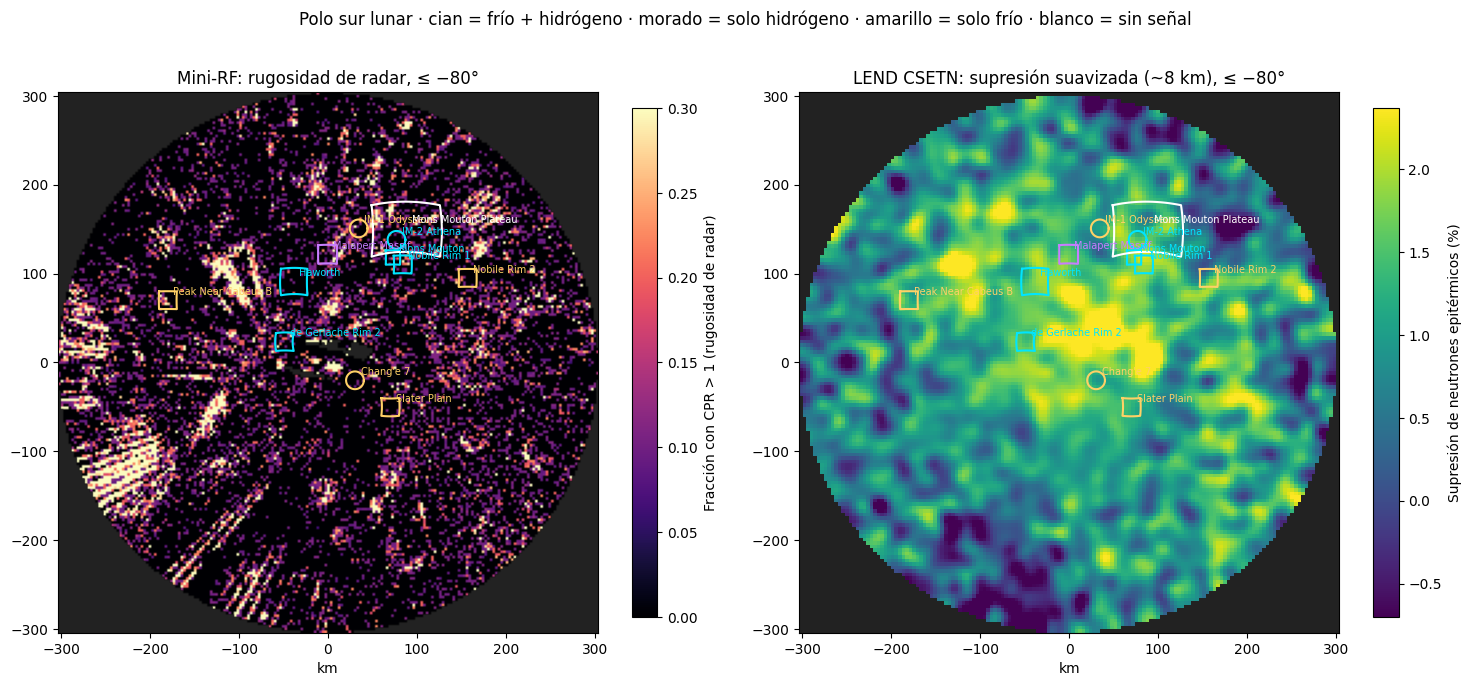

In [14]:
colores = {"frío + hidrógeno": "#00e5ff", "solo hidrógeno": "#c77dff", "solo frío": "#ffd166", "sin señal": "#ffffff"}


def contorno(geom):
    if geom.geom_type == "MultiPolygon":
        geom = max(geom.geoms, key=lambda g: g.area)
    return geom.exterior.xy


def rejilla_media(x, y, v, w=None, paso=2.0, sigma_km=0.0):
    # Media (ponderada) en una rejilla cuadrada; con sigma_km > 0 se suaviza sumas y pesos por separado
    lim = RHO_CASQUETE
    bins = np.arange(-lim, lim + paso, paso)
    w = np.ones_like(v) if w is None else w
    suma, _, _ = np.histogram2d(x, y, bins=[bins, bins], weights=v * w)
    peso, _, _ = np.histogram2d(x, y, bins=[bins, bins], weights=w)
    if sigma_km > 0:
        suma, peso = gaussian_filter(suma, sigma_km / paso), gaussian_filter(peso, sigma_km / paso)
    with np.errstate(invalid="ignore", divide="ignore"):
        media = suma / peso
    rho = np.hypot(*np.meshgrid((bins[:-1] + bins[1:]) / 2, (bins[:-1] + bins[1:]) / 2, indexing="ij"))
    media[rho > lim] = np.nan
    return media.T, lim


fig, ejes = plt.subplots(1, 2, figsize=(15, 7))
img, lim = rejilla_media(px_x, px_y, (px_v > 1).astype(float), paso=3.0)
im = ejes[0].imshow(img, origin="lower", extent=[-lim, lim, -lim, lim], cmap="magma", vmin=0, vmax=0.3)
plt.colorbar(im, ax=ejes[0], shrink=0.8, label="Fracción con CPR > 1 (rugosidad de radar)")
ejes[0].set_title("Mini-RF: rugosidad de radar, ≤ −80°")

img, lim = rejilla_media(lend["x"].to_numpy(), lend["y"].to_numpy(), lend["sup"].to_numpy() * 100,
                         w=1 / lend["sup_err"].to_numpy() ** 2, paso=4.0, sigma_km=8.0)
vmin, vmax = np.nanpercentile(img, [2, 98])
im = ejes[1].imshow(img, origin="lower", extent=[-lim, lim, -lim, lim], cmap="viridis", vmin=vmin, vmax=vmax)
plt.colorbar(im, ax=ejes[1], shrink=0.8, label="Supresión de neutrones epitérmicos (%)")
ejes[1].set_title("LEND CSETN: supresión suavizada (~8 km), ≤ −80°")

for ax in ejes:
    for _, s in sitios.iterrows():
        x, y = contorno(s.geom)
        ax.plot(x, y, color=colores[s.nivel_hielo], lw=1.5)
        ax.annotate(s.nombre, (s.cx, s.cy), fontsize=7, color=colores[s.nivel_hielo], xytext=(4, 4), textcoords="offset points")
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("km")
    ax.set_facecolor("#222")
fig.suptitle("Polo sur lunar · cian = frío + hidrógeno · morado = solo hidrógeno · amarillo = solo frío · blanco = sin señal")
plt.tight_layout()
fig.savefig(FIG / "mapa_rugosidad_lend_sitios.png", dpi=150)
plt.show()

In [15]:
# Zoom alrededor de cada sitio: CPR de Mini-RF. La ventana se adapta al tamaño del sitio (mínimo 40 km)
n = len(sitios)
cols = 4
fig, ejes = plt.subplots(math.ceil(n / cols), cols, figsize=(4 * cols, 4 * math.ceil(n / cols)))
for ax, (_, s) in zip(np.ravel(ejes), sitios.iterrows()):
    minx, miny, maxx, maxy = s.geom.bounds
    medio = max(20.0, (maxx - minx) / 2 + 5, (maxy - miny) / 2 + 5)
    m = (np.abs(px_x - s.cx) < medio) & (np.abs(px_y - s.cy) < medio)
    ax.scatter(px_x[m], px_y[m], c=px_v[m], s=max(1.0, 6 * (20 / medio) ** 2), cmap="magma", vmin=0, vmax=1.5)
    x, y = contorno(s.geom)
    ax.plot(x, y, color=colores[s.nivel_hielo], lw=2)
    ax.set_xlim(s.cx - medio, s.cx + medio)
    ax.set_ylim(s.cy - medio, s.cy + medio)
    ax.set_title(f"{s.nombre}\n{s.nivel_hielo} · rugosidad {s.rugosidad_radar}", fontsize=9)
    ax.set_aspect("equal")
    ax.set_facecolor("#222")
    ax.set_xticks([])
    ax.set_yticks([])
for ax in np.ravel(ejes)[n:]:
    ax.axis("off")
plt.tight_layout()
fig.savefig(FIG / "zoom_minirf_sitios.png", dpi=130)
plt.show()

Output hidden; open in https://colab.research.google.com to view.

## 8. Exportación

- CSV completo y CSV de la prueba de sensibilidad en `04_resultados/hielo_v1.1/`.
- JSON para la web en `06_web/hielo_v1.1/hielo_lro.json` (clave por sitio = `sitio_id`, como `sitios_v0`).
- La entrada `hielo_lro` de `manifest.json` pasa a apuntar a v1.1.

In [16]:
def limpio(v):
    # NaN -> None y tipos de numpy -> tipos de Python, para que el JSON sea válido
    if isinstance(v, (np.floating, float)):
        return None if not np.isfinite(v) else round(float(v), 4)
    if isinstance(v, np.integer):
        return int(v)
    if isinstance(v, np.bool_):
        return bool(v)
    return v


columnas_csv = [
    "sitio_id", "nombre", "tipo", "lat", "lon", "area_km2",
    "diviner_f_hielo", "diviner_prof_hielo", "senal_diviner",
    "lend_supresion", "lend_err", "lend_n_celdas", "lend_mediana_polo", "lend_exceso", "lend_z_polo",
    "lend_percentil", "senal_lend", "lend_radios_con_senal", "lend_robusta",
    "nivel_hielo",
    "minirf_cpr_mediana", "minirf_cpr_p90", "minirf_frac_cpr_gt1", "minirf_frac_cpr_gt1_anillo", "minirf_n_px",
    "rugosidad_radar_percentil", "rugosidad_radar",
    "pareja_hielo_tierra", "analogo_hielo_terreno_v0",
]
sitios[columnas_csv].to_csv(RES / "hielo_lro_sitios.csv", index=False)
sensibilidad.to_csv(RES / "sensibilidad_lend.csv", index=False)

fuentes = [
    {"instrumento": "Diviner PRP", "producto": "LRO-L-DLRE (vía hielo_v0)", "url": "https://pds-geosciences.wustl.edu/missions/lro/diviner.htm"},
    {"instrumento": "Mini-RF", "producto": "LRO-L-MRFLRO-5-GLOBAL-MOSAIC-V1.0, CPR 32 ppd", "url": URL_MINIRF_CPR},
    {"instrumento": "LEND", "producto": "LRO-L-LEND-4/5-RDR-V1.0, ALD polo sur", "url": LEND_DATA},
]
web = {
    "version": VERSION,
    "generado": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "descripcion": (
        "Hielo en los sitios del polo sur lunar con dos pruebas independientes de LRO: Diviner (frío suficiente "
        "para que el hielo sea estable) y LEND (más hidrógeno que el resto del polo). Mini-RF se da como rugosidad "
        "de radar (bloques a escala de decímetros), no como prueba de hielo."
    ),
    "unidades": {
        "diviner_f_hielo": "fracción del sitio con hielo estable cerca de la superficie (0–1)",
        "lend_supresion": "supresión de neutrones epitérmicos CSETN frente a 55–60° S (0–1; sin restar el fondo de la nave)",
        "lend_exceso": "supresión del sitio menos la mediana de 2000 discos al azar del casquete ≤ −80°",
        "lend_z_polo": "lend_exceso / error estadístico (ruido de conteo)",
        "lend_percentil": "percentil de la supresión frente a los discos al azar (recoge sistemáticos y variación natural)",
        "lend_radios_con_senal": f"radios de la prueba de sensibilidad {list(RADIOS_SENSIBILIDAD)} km con señal de LEND",
        "nivel_hielo": "frío + hidrógeno · solo frío · solo hidrógeno · sin señal",
        "minirf_frac_cpr_gt1": "fracción del sitio con CPR > 1 (banda S)",
        "rugosidad_radar": f"baja / media / alta según el percentil frente al polo (cortes {list(PCT_RUGOSIDAD)})",
    },
    "umbrales": {"diviner_f_hielo": UMBRAL_HIELO, "lend_z_polo": Z_POLO, "lend_percentil": PCT_SENAL},
    "parametros": {
        "radio_punto_km": RADIO_PUNTO_KM, "radio_lend_km": RADIO_LEND_KM, "radios_sensibilidad_km": list(RADIOS_SENSIBILIDAD),
        "lat_casquete": LAT_CASQUETE, "n_discos_azar": N_DISCOS_AZAR,
    },
    "sitios": {s["sitio_id"]: {k: limpio(s[k]) for k in columnas_csv if k != "sitio_id"} for _, s in sitios.iterrows()},
    "fuentes": fuentes,
    "nota": "Unir con 06_web/sitios_v0/sitios.geojson por id. La supresión de LEND solo sirve para comparar lugares entre sí.",
}
(WEB / VERSION / "hielo_lro.json").write_text(json.dumps(web, ensure_ascii=False, indent=1), encoding="utf-8")

registro = {
    "notebook": f"{VERSION}.ipynb",
    "ejecutado": web["generado"],
    "parametros": web["parametros"] | web["umbrales"],
    "fuentes": fuentes,
    "conteos": {
        "sitios": int(len(sitios)),
        "niveles_hielo": sitios["nivel_hielo"].value_counts().to_dict(),
        "lend_robusta": int(sitios["lend_robusta"].sum()),
        "rugosidad_radar": sitios["rugosidad_radar"].value_counts().to_dict(),
        "pixeles_minirf": int(len(px_v)),
        "celdas_lend": int(len(lend)),
    },
}
(RES / f"registro_{VERSION}.json").write_text(json.dumps(registro, ensure_ascii=False, indent=1), encoding="utf-8")

if ACTUALIZAR_MANIFEST:
    ruta_m = WEB / "manifest.json"
    manifest = json.loads(ruta_m.read_text(encoding="utf-8"))
    manifest.setdefault("capas", {})["hielo_lro"] = {"version": VERSION, "carpeta": VERSION, "archivo": f"{VERSION}/hielo_lro.json"}
    ruta_m.write_text(json.dumps(manifest, ensure_ascii=False, indent=1), encoding="utf-8")
    print(f"Capa «hielo_lro» apunta ahora a {VERSION} en manifest.json")

print("Escrito:", RES / "hielo_lro_sitios.csv", "·", RES / "sensibilidad_lend.csv", "·", WEB / VERSION / "hielo_lro.json")

Capa «hielo_lro» apunta ahora a hielo_v1.1 en manifest.json
Escrito: /content/drive/MyDrive/Hackathon Nasa/04_resultados/hielo_v1.1/hielo_lro_sitios.csv · /content/drive/MyDrive/Hackathon Nasa/04_resultados/hielo_v1.1/sensibilidad_lend.csv · /content/drive/MyDrive/Hackathon Nasa/06_web/hielo_v1.1/hielo_lro.json


## 9. Limitaciones

- **Estable no es presente.** Diviner dice dónde el hielo *podría* conservarse, no si llegó ni cuánto hay.
- **LEND:** mancha en el suelo de ~10–20 km; más de la mitad de la señal de CSETN es fondo de la nave, sin restar.
  El error estadístico solo cubre el ruido de conteo (las celdas cuentan neutrones distintos, así que ese ruido sí
  es independiente); los **sistemáticos** (fondo, altura de la órbita, deriva de los detectores) no están en él.
  Por eso la señal exige también el percentil frente al polo.
- **Escalas distintas:** Diviner resuelve trampas frías de cientos de metros; LEND promedia ~20 km. Un sitio con
  trampas frías pequeñas puede no destacar en LEND aunque tenga hielo en ellas.
- **Mini-RF:** mide rugosidad a escala de decímetros; mira de lado (~48°), así que las laderas orientadas hacia el
  radar salen más brillantes; mosaico no controlado (desfase de ~1–2 km) y con huecos cerca del polo.
- **Pocos sitios** (12): las correlaciones son orientativas.
- No hay sitios al norte de −80° (la rejilla polar de LEND empieza en −80°).

## 10. Conclusiones (ejecución del 14 nov 2026)

**Resumen en una frase:** 5 de los 12 sitios tienen frío **y** más hidrógeno que el resto del polo, pero ese hidrógeno es **regional** (LEND no lo resuelve por debajo de ~20 km); IM-1 Odysseus queda como el caso más claro de «frío sin hidrógeno», y Mini-RF se confirma como medida de rugosidad.

### Resultados

1. **Niveles de hielo:** 5 frío + hidrógeno, 5 solo frío, 1 solo hidrógeno y 1 sin señal.

   | Sitio | Diviner `f_hielo` | LEND z (15 / 20 / 30 km) | Percentil LEND | Nivel | Rugosidad de radar |
   |---|---|---|---|---|---|
   | de Gerlache Rim 2 | 0,26 | 1,6 / 2,5 / 4,0 | 87 | frío + hidrógeno | media |
   | IM-2 Athena | 0,45 | 2,0 / 2,3 / 3,1 | 89 | frío + hidrógeno | baja |
   | Nobile Rim 1 | 0,35 | 1,9 / 2,2 / 4,0 | 89 | frío + hidrógeno | media |
   | Haworth | 0,62 | 1,6 / 2,2 / 3,4 | 80 | frío + hidrógeno | baja |
   | **Mons Mouton** | 0,46 | 2,2 / 2,0 / 4,1 | 87 | frío + hidrógeno (**robusta**: los tres radios) | media |
   | Malapert Massif | 0,21 | 1,9 / 2,0 / 2,9 | 82 | solo hidrógeno | **alta** |
   | Chang'e 7 | 0,39 | 0,3 / 1,7 / 4,4 | 75 | solo frío | baja |
   | Slater Plain | 0,54 | 0,6 / 1,3 / 1,5 | 70 | solo frío | baja |
   | Peak Near Cabeus B | 0,29 | 0,9 / 1,1 / 0,5 | 79 | solo frío | media |
   | Nobile Rim 2 | 0,34 | 0,2 / −0,1 / 0,3 | 47 | solo frío | media |
   | **IM-1 Odysseus** | **0,97** | −0,8 / −0,2 / −0,1 | 46 | solo frío | media |
   | Mons Mouton Plateau | 0,19 | 0,6 / 0,3 / 1,4 | 57 | sin señal | **alta** |

2. **Respecto a v1:** Chang'e 7 y Peak Near Cabeus B pierden la señal de LEND, como se esperaba con la nueva regla. Los demás conservan el veredicto.

3. **El hidrógeno es regional, no de cada sitio.** Solo Mons Mouton tiene señal con los tres radios. En los otros cuatro «frío + hidrógeno», la z casi se duplica al pasar de 15 a 30 km. Eso es justo lo que pasa si el exceso **se mantiene** al ampliar el área (el error se reduce a la mitad con cuatro veces más celdas): el exceso no está concentrado dentro del sitio, sino repartido en una zona más amplia. En el mapa se ve una región enriquecida entre Haworth, de Gerlache Rim 2, Malapert, Mons Mouton y Nobile Rim 1. A 15 km casi ninguna señal pasa: **LEND no resuelve los sitios por debajo de ~20 km**. Que el hidrógeno de LEND no coincida exactamente con las zonas en sombra permanente ya lo señalaron Mitrofanov et al. (2010).

4. **IM-1 Odysseus es el resultado negativo más sólido.** Tiene la mayor fracción de hielo estable de todos los sitios (0,97) y ningún exceso de hidrógeno con ningún radio (z entre −0,8 y −0,1). Está en el borde de la región enriquecida, fuera de ella.

5. **Mini-RF = rugosidad, confirmado.** Diviner `f_hielo` frente a la fracción con CPR > 1: ρ = −0,73 (p = 0,007). Mini-RF no se relaciona con LEND (ρ = −0,03), ni Diviner con LEND (ρ = −0,08): miden cosas distintas a escalas distintas.

### Parejas de hielo de `hielo_v0`

| Pareja | Veredicto v1.1 |
|---|---|
| **Nobile Rim 1 ↔ Pamir** | **Se mantiene**: frío + hidrógeno, pero el hidrógeno es de la región, no del sitio |
| **IM-2 Athena ↔ Askja** | **Se mantiene**: frío + hidrógeno; además, rugosidad de radar baja |
| **IM-1 Odysseus ↔ Axel Heiberg** | **Debilitada** (con los tres radios): solo frío. La analogía funciona en temperatura, no en hielo presente |

### Regiones Artemis por uso (enfoque D)

- **Agua, hielo y permafrost:** **Mons Mouton** (la única señal robusta de LEND, con frío 0,46) y **Haworth** (el sitio Artemis más frío, 0,62, con hidrógeno a 20 y 30 km). Después Nobile Rim 1 y de Gerlache Rim 2.
- **Aterrizaje y movilidad (rugosidad de radar):** las más lisas son **Haworth**, Slater Plain, IM-2 y Chang'e 7; las más rugosas, **Malapert Massif** y **Mons Mouton Plateau**. Esto es rugosidad a escala de decímetros; las pendientes salen de la capa de topografía.
- **Haworth combina las dos cosas**: el más frío, con hidrógeno regional y de los más lisos para el radar.

### Qué cambia en el proyecto

- **Capa `hielo_lro` (v1.1)** lista para el backend: `nivel_hielo`, `lend_robusta` y `rugosidad_radar` por sitio.
- **Enfoque D:** el uso «agua, hielo y permafrost» toma `nivel_hielo`; «aterrizaje y movilidad» puede sumar `rugosidad_radar` a la topografía.
- **Base de análogos y ficha:** bajar la confianza de la pareja IM-1 ↔ Axel Heiberg en lo que se refiere al hielo; anotar en Nobile Rim 1 ↔ Pamir e IM-2 ↔ Askja que el hidrógeno es regional.
- **Pitch:** (1) dos pruebas independientes y una prueba de sensibilidad, no un solo instrumento; (2) «estable no es presente» (IM-1); (3) dónde falla la analogía: en la Tierra el hielo es masivo; en la Luna el hidrógeno es escaso, repartido y regional (incluso en Cabeus, el punto más rico, 0,5–4 % de hielo en peso según LEND; Mitrofanov et al., 2010).

### Pendiente

- Sincronizar `06_web/hielo_v1.1` y el `manifest.json` con el backend (rama `feat/datos-…`).
- Actualizar la base de análogos y la ficha con estos veredictos.
- Añadir Mini-RF y LEND a la bibliografía de Drive.
- Limitación a tener en cuenta: el mosaico de Mini-RF tiene franjas de órbitas (rayas en los bordes del mapa) y un hueco cerca del polo que cruza de Gerlache Rim 2; no cambian los veredictos, pero inflan un poco la rugosidad de los discos al azar.

**Referencias:** Mitrofanov et al. (2010), *Science* 330, 483–486 · Eke et al. (2014), *Icarus* · Spudis et al. (2013), *JGR Planets* · Datos: LRO Mini-RF, LEND y Diviner (PDS Geosciences).